In [1]:
# Import all the necessary moduls and libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

In [2]:
# Load Datasets
df = pd.read_csv("../data/Churn-Prediction-dataset.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Convert data type to int
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors='coerce'
)  

1869


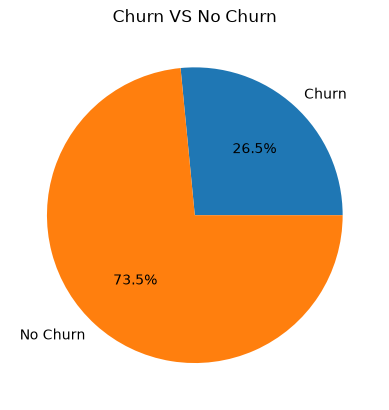

In [5]:
Churn = (df["Churn"] == "Yes").sum()
No_churn = (df["Churn"] == "No").sum()

h = Churn + No_churn + 100
x = [45,55]
print(Churn)

plt.pie([Churn, No_churn],
       labels=["Churn","No Churn"],
       autopct="%1.1f%%",
       )
plt.title("Churn VS No Churn")
plt.show()

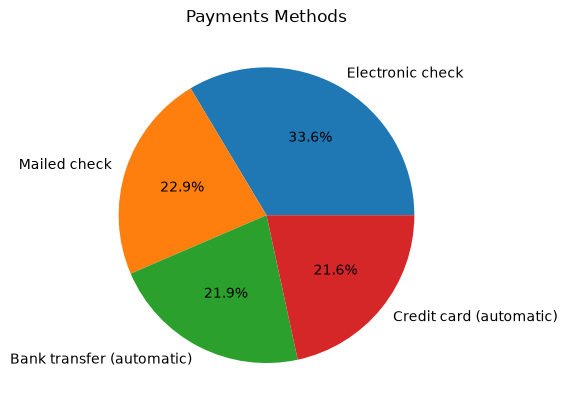

In [6]:
payment_methods = [(df["PaymentMethod"] == 'Electronic check').sum(), ((df["PaymentMethod"] == "Mailed check").sum()), (df["PaymentMethod"] == "Bank transfer (automatic)").sum(), (df["PaymentMethod"] == "Credit card (automatic)").sum()]
labels = ["Electronic check", "Mailed check", "Bank transfer (automatic)","Credit card (automatic)"]

plt.pie(payment_methods,
       labels=labels,
       autopct= "%1.1f%%"
)
plt.title("Payments Methods")
plt.show()

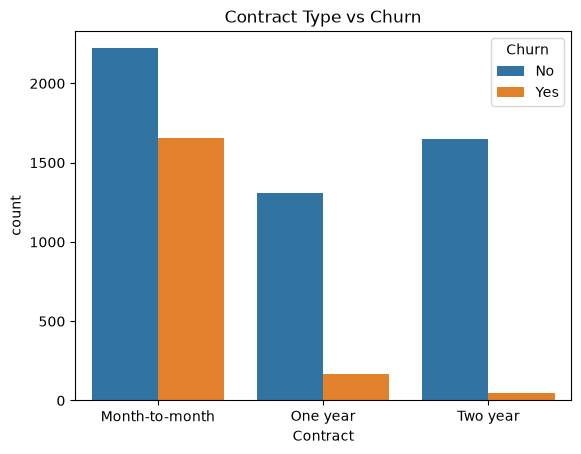

In [7]:
cont_data = pd.DataFrame({
    "Contract" : df["Contract"],
    "Churn" : df["Churn"]
})


sns.countplot(data=df, x=df["Contract"], hue=df["Churn"])
plt.title("Contract Type vs Churn")
plt.show()

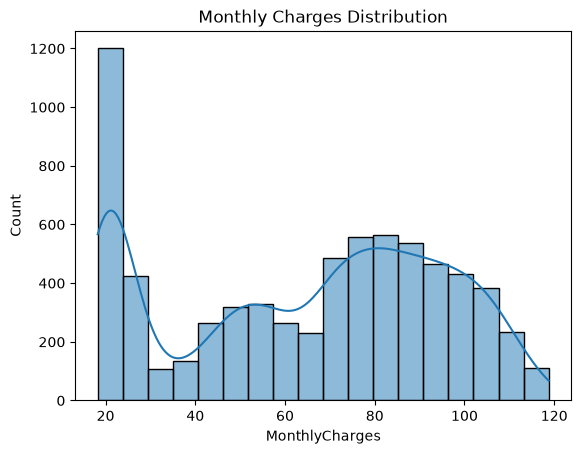

In [8]:
sns.histplot(df["MonthlyCharges"], kde=True)
plt.title("Monthly Charges Distribution")
plt.show()

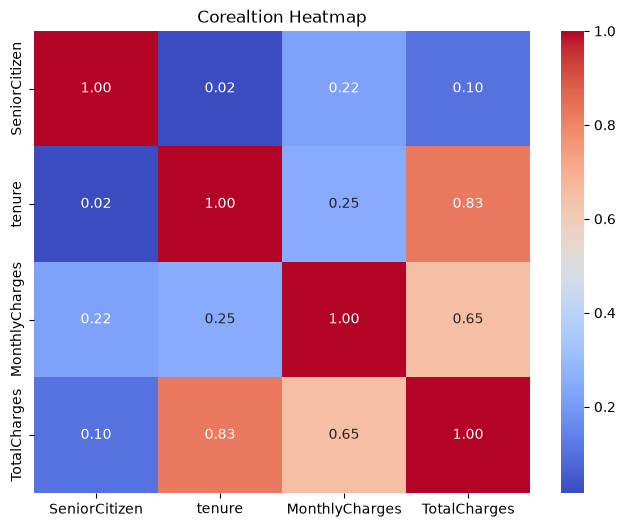

In [9]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(8,6))
sns.heatmap(corr,
            annot=True,
            fmt=".2f",       
            cmap="coolwarm")
plt.title("Corealtion Heatmap")
plt.show()

In [10]:
# Split Datasets int input and output
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

In [11]:
# convert Churn Value into 0 and 1
y = y.map({"Yes" : 1, "No" : 0})

In [12]:
# Split Datasets into trainig and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [13]:
# Use simpleimputer to fill values
mean_imputer = SimpleImputer(strategy='mean')
X_train["TotalCharges"] = mean_imputer.fit_transform(X_train[["TotalCharges"]])
X_test["TotalCharges"] = mean_imputer.transform(X_test[["TotalCharges"]])

In [14]:
# Divide columns into binary, category and numaric based on thier value
binary_cols = [
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
    "gender"
]

categorical_cols  = [
    "OnlineSecurity",
    "OnlineBackup",
    "MultipleLines",
    "InternetService",
    "InternetService",
    "StreamingMovies",
    "Contract",
    "PaymentMethod",
    "DeviceProtection",
    'TechSupport',
    'StreamingTV'
]

numeric_col = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Preprocesser For Logistic Regression and K Nearest Neighbor

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("binary",OrdinalEncoder(), binary_cols),
        ("cat", OneHotEncoder(drop="first",handle_unknown='ignore'), categorical_cols),
        ("num", StandardScaler(), numeric_col)
    ],
    remainder="passthrough"
)

# Logistic Regression

In [16]:
lg_model = LogisticRegression(
    C=1,
    max_iter=1000,
    penalty="l1",
    solver="liblinear"
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", lg_model)
])

# Rebuild the target safely and remove rows with missing labels
y = df["Churn"].astype(str).str.strip().map({"Yes": 1, "No": 0})
valid_idx = y.notna()

X = df.loc[valid_idx, :].drop(columns=["customerID", "Churn"])
y = y.loc[valid_idx].astype("int64")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fill the only feature that can still contain NaNs after the split
X_train = X_train.copy()
X_test = X_test.copy()

median_total_charges = X_train["TotalCharges"].median()
X_train["TotalCharges"] = X_train["TotalCharges"].fillna(median_total_charges)
X_test["TotalCharges"] = X_test["TotalCharges"].fillna(median_total_charges)

pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.8026969481902059
Precision Score:  0.6509433962264151
Recall Score:  0.553475935828877
F1 Score:  0.5982658959537572
ROC AUC Score:  0.7231147795086413


In [29]:
joblib.dump(pipeline, "../models/Logistic_Regression.pkl")

['../models/Logistic_Regression.pkl']

## K Nearest Neighbors

In [30]:
knn_model = KNeighborsClassifier()

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", knn_model)
])

knn_pipeline.fit(X_train, y_train)
pred = knn_pipeline.predict(X_test)


print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.7622427253371186
Precision Score:  0.5525606469002695
Recall Score:  0.5481283422459893
F1 Score:  0.5503355704697986
ROC AUC Score:  0.6938709344080187


## Hyperparameter Tunnig For KNN

In [31]:
n_neighbors = [20, 25,30,35,40,45,50]

for n in n_neighbors:
    knn_model = KNeighborsClassifier(
        n_neighbors=n
    )
    
    knn_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", knn_model)
    ])
    
    knn_pipeline.fit(X_train, y_train)
    pred = knn_pipeline.predict(X_test)
    
    print("Score for n neigbhor for", n)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score for n neigbhor for 20
Accuracy Score:  0.7892122072391767
Precision Score:  0.617737003058104
Recall Score:  0.5401069518716578
F1 Score:  0.5763195435092725
ROC AUC Score:  0.7096670025058772
Score for n neigbhor for 25
Accuracy Score:  0.7920511000709723
Precision Score:  0.6173913043478261
Recall Score:  0.56951871657754
F1 Score:  0.5924895688456189
ROC AUC Score:  0.7209912423467411
Score for n neigbhor for 30
Accuracy Score:  0.801277501774308
Precision Score:  0.6398809523809523
Recall Score:  0.5748663101604278
F1 Score:  0.6056338028169014
ROC AUC Score:  0.7289790488000207
Score for n neigbhor for 35
Accuracy Score:  0.7963094393186657
Precision Score:  0.6218487394957983
Recall Score:  0.5935828877005348
F1 Score:  0.6073871409028728
ROC AUC Score:  0.7315740525459196
Score for n neigbhor for 40
Accuracy Score:  0.7927608232789212
Precision Score:  0.6234939759036144
Recall Score:  0.553475935828877
F1 Score:  0.5864022662889519
ROC AUC Score:  0.7163514944844869
Score

In [32]:
leaf_size = [30,35, 40,45,50,55,60]

for n in leaf_size:
    knn_model = KNeighborsClassifier(
        n_neighbors=45,
        leaf_size=n
    )
    
    knn_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", knn_model)
    ])
    
    knn_pipeline.fit(X_train, y_train)
    pred = knn_pipeline.predict(X_test)
    
    print("Score for leaf_size for", n)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score for leaf_size for 30
Accuracy Score:  0.7927608232789212
Precision Score:  0.6198830409356725
Recall Score:  0.5668449197860963
F1 Score:  0.5921787709497207
ROC AUC Score:  0.7206205275258983
Score for leaf_size for 35
Accuracy Score:  0.7927608232789212
Precision Score:  0.6198830409356725
Recall Score:  0.5668449197860963
F1 Score:  0.5921787709497207
ROC AUC Score:  0.7206205275258983
Score for leaf_size for 40
Accuracy Score:  0.7927608232789212
Precision Score:  0.6198830409356725
Recall Score:  0.5668449197860963
F1 Score:  0.5921787709497207
ROC AUC Score:  0.7206205275258983
Score for leaf_size for 45
Accuracy Score:  0.7927608232789212
Precision Score:  0.6198830409356725
Recall Score:  0.5668449197860963
F1 Score:  0.5921787709497207
ROC AUC Score:  0.7206205275258983
Score for leaf_size for 50
Accuracy Score:  0.7927608232789212
Precision Score:  0.6198830409356725
Recall Score:  0.5668449197860963
F1 Score:  0.5921787709497207
ROC AUC Score:  0.7206205275258983
Score

In [33]:
metric = ['euclidean', 'manhattan', 'minkowski']

for n in metric:
    knn_model = KNeighborsClassifier(
        n_neighbors=45,
        metric=n
    )
    
    knn_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", knn_model)
    ])
    
    knn_pipeline.fit(X_train, y_train)
    pred = knn_pipeline.predict(X_test)
    
    print("Score for metric for", n)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score for metric for euclidean
Accuracy Score:  0.7927608232789212
Precision Score:  0.6198830409356725
Recall Score:  0.5668449197860963
F1 Score:  0.5921787709497207
ROC AUC Score:  0.7206205275258983
Score for metric for manhattan
Accuracy Score:  0.7899219304471257
Precision Score:  0.6120689655172413
Recall Score:  0.56951871657754
F1 Score:  0.590027700831025
ROC AUC Score:  0.7195419669844221
Score for metric for minkowski
Accuracy Score:  0.7927608232789212
Precision Score:  0.6198830409356725
Recall Score:  0.5668449197860963
F1 Score:  0.5921787709497207
ROC AUC Score:  0.7206205275258983


In [34]:
# KNN Best Model

knn_best_model = KNeighborsClassifier(
    n_neighbors=45
)

Knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", knn_model)
])

knn_pipeline.fit(X_train, y_train)
pred = knn_pipeline.predict(X_test)

print("Score for metric for", n)
print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score for metric for minkowski
Accuracy Score:  0.7927608232789212
Precision Score:  0.6198830409356725
Recall Score:  0.5668449197860963
F1 Score:  0.5921787709497207
ROC AUC Score:  0.7206205275258983


In [35]:
joblib.dump(knn_pipeline, '../models/KNN.pkl')

['../models/KNN.pkl']

In [36]:
# Grid Search Cv for KNN
model = KNeighborsClassifier()

param_grid = {
    "model__n_neighbors": range(35, 61, 5),
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan", "minkowski"],
    "model__p": [1, 2]
}

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

grid = GridSearchCV(
    knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)
print(grid.best_params_)
print(grid.best_score_)

{'model__metric': 'manhattan', 'model__n_neighbors': 35, 'model__p': 1, 'model__weights': 'uniform'}
0.6103140990364018


In [37]:
# Knn Model Based On Gridsearchcv result

grid_knn_model = KNeighborsClassifier(
    metric='manhattan',
    n_neighbors=35,
    p=1,
    weights='uniform'
)

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

knn_pipeline.fit(X_train, y_train)
pred = knn_pipeline.predict(X_test)


print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.7622427253371186
Precision Score:  0.5525606469002695
Recall Score:  0.5481283422459893
F1 Score:  0.5503355704697986
ROC AUC Score:  0.6938709344080187


# Preprocessor for Decision Tree, Random Forest, XGBoost

In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        ("binary",OrdinalEncoder(), binary_cols),
        ("cat", OneHotEncoder(drop="first",handle_unknown='ignore'), categorical_cols)
    ],
    remainder="passthrough"
)

## Decision Tree

In [39]:
Dt_model = DecisionTreeClassifier()

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Dt_model)
])

pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.7423704755145494
Precision Score:  0.5150684931506849
Recall Score:  0.5026737967914439
F1 Score:  0.5087956698240866
ROC AUC Score:  0.6658296520189103


## Hyperparameter Tunnig For Decision Tree

In [40]:
for depth in [3, 5, 7, 10, 15, 20]:
    Dt_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Dt_model)
    ])
    
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.78708303761533
Precision Score:  0.6681818181818182
Recall Score:  0.393048128342246
F1 Score:  0.494949494949495
ROC AUC Score:  0.6612583636880311
Accuracy Score:  0.794180269694819
Precision Score:  0.6296296296296297
Recall Score:  0.5454545454545454
F1 Score:  0.5845272206303725
ROC AUC Score:  0.7147562582345192
Accuracy Score:  0.7920511000709723
Precision Score:  0.6238532110091743
Recall Score:  0.5454545454545454
F1 Score:  0.5820256776034237
ROC AUC Score:  0.7133069828722003
Accuracy Score:  0.7551454932576295
Precision Score:  0.5370843989769821
Recall Score:  0.5614973262032086
F1 Score:  0.5490196078431373
ROC AUC Score:  0.6933090495750343
Accuracy Score:  0.7388218594748048
Precision Score:  0.5079787234042553
Recall Score:  0.5106951871657754
F1 Score:  0.5093333333333333
ROC AUC Score:  0.6659756129065592
Accuracy Score:  0.7374024130589071
Precision Score:  0.5054347826086957
Recall Score:  0.49732620320855614
F1 Score:  0.5013477088948787
ROC AUC

In [41]:
for depth in [2, 5, 10, 20]:
    Dt_model = DecisionTreeClassifier(
        max_depth=7,
        min_samples_split = depth,
        random_state=42
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Dt_model)
    ])
    
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    print("Score For min_samples_split :", depth)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score For min_samples_split : 2
Accuracy Score:  0.7920511000709723
Precision Score:  0.6238532110091743
Recall Score:  0.5454545454545454
F1 Score:  0.5820256776034237
ROC AUC Score:  0.7133069828722003
Score For min_samples_split : 5
Accuracy Score:  0.7920511000709723
Precision Score:  0.6238532110091743
Recall Score:  0.5454545454545454
F1 Score:  0.5820256776034237
ROC AUC Score:  0.7133069828722003
Score For min_samples_split : 10
Accuracy Score:  0.7906316536550745
Precision Score:  0.6215384615384615
Recall Score:  0.5401069518716578
F1 Score:  0.5779685264663805
ROC AUC Score:  0.7106331860807564
Score For min_samples_split : 20
Accuracy Score:  0.7913413768630234
Precision Score:  0.6234567901234568
Recall Score:  0.5401069518716578
F1 Score:  0.5787965616045845
ROC AUC Score:  0.711116277868196


In [42]:
for depth in [2, 5, 10, 20, 25]:
    Dt_model = DecisionTreeClassifier(
        max_depth=7,
        min_samples_split=20,
        random_state=42,
        min_samples_leaf = depth
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Dt_model)
    ])
    
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    print("Score For min_samples_leaf  :", depth)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score For min_samples_leaf  : 2
Accuracy Score:  0.7927608232789212
Precision Score:  0.6273291925465838
Recall Score:  0.5401069518716578
F1 Score:  0.5804597701149425
ROC AUC Score:  0.7120824614430753
Score For min_samples_leaf  : 5
Accuracy Score:  0.7927608232789212
Precision Score:  0.617816091954023
Recall Score:  0.5748663101604278
F1 Score:  0.5955678670360111
ROC AUC Score:  0.7231819473507453
Score For min_samples_leaf  : 10
Accuracy Score:  0.7991483321504613
Precision Score:  0.645367412140575
Recall Score:  0.5401069518716578
F1 Score:  0.5880640465793304
ROC AUC Score:  0.7164302875300318
Score For min_samples_leaf  : 20
Accuracy Score:  0.7955997161107168
Precision Score:  0.6242774566473989
Recall Score:  0.5775401069518716
F1 Score:  0.6
ROC AUC Score:  0.7259681211087862
Score For min_samples_leaf  : 25
Accuracy Score:  0.7977288857345636
Precision Score:  0.6297376093294461
Recall Score:  0.5775401069518716
F1 Score:  0.602510460251046
ROC AUC Score:  0.727417396471

In [43]:
for depth in ["gini", "entropy"]:
    Dt_model = DecisionTreeClassifier(
        max_depth=7,
        min_samples_split=20,
        random_state=42,
        min_samples_leaf = 20,
        criterion =depth
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Dt_model)
    ])
    
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    print("Score For criterion   :", depth)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score For criterion   : gini
Accuracy Score:  0.7955997161107168
Precision Score:  0.6242774566473989
Recall Score:  0.5775401069518716
F1 Score:  0.6
ROC AUC Score:  0.7259681211087862
Score For criterion   : entropy
Accuracy Score:  0.8019872249822569
Precision Score:  0.6970954356846473
Recall Score:  0.44919786096256686
F1 Score:  0.5463414634146342
ROC AUC Score:  0.6893332299981917


In [44]:
Best_Dt_model = DecisionTreeClassifier(
    max_depth=7,
    min_samples_split=20,
    min_samples_leaf=20,
    criterion="gini",
    random_state=42
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Best_Dt_model)
])

pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.7955997161107168
Precision Score:  0.6242774566473989
Recall Score:  0.5775401069518716
F1 Score:  0.6
ROC AUC Score:  0.7259681211087862


In [45]:
# Gridsearccv test

param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [5, 7, 10],
    "model__min_samples_split": [10, 20, 30],
    "model__min_samples_leaf": [10, 20, 30]
}

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train, y_train)

print("Best Params:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best Params: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__min_samples_leaf': 30, 'model__min_samples_split': 10}
Best CV Score: 0.5607564312569792


In [46]:
grid_Dt_Model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_leaf=20,
    min_samples_split=10,
    random_state=42
)

grid_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", grid_Dt_Model)
])

grid_pipeline.fit(X_train, y_train)
pred = grid_pipeline.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.7955997161107168
Precision Score:  0.6335403726708074
Recall Score:  0.5454545454545454
F1 Score:  0.5862068965517241
ROC AUC Score:  0.7157224418093983


In [47]:
joblib.dump(pipeline, "../models/DecisionTreeModel.pkl")

['../models/DecisionTreeModel.pkl']

## Random Forest

In [48]:
RF_model = RandomForestClassifier()

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RF_model)
])

pipeline.fit(X_train, y_train)

pred = pipeline.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.7877927608232789
Precision Score:  0.6271186440677966
Recall Score:  0.4946524064171123
F1 Score:  0.5530642750373692
ROC AUC Score:  0.6941861065901986


## Hyperparameter Tunning for Random Forest

In [49]:
n_estimators = [25, 40, 50, 100, 200, 300]

for n in n_estimators:
    RF_model = RandomForestClassifier(
        n_estimators=n
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RF_model)
    ])
    
    pipeline.fit(X_train, y_train)
    
    pred = pipeline.predict(X_test)

    print("Score For n_estimators   :", n)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score For n_estimators   : 25
Accuracy Score:  0.7842441447835344
Precision Score:  0.6129032258064516
Recall Score:  0.5080213903743316
F1 Score:  0.5555555555555556
ROC AUC Score:  0.6960396806944122
Score For n_estimators   : 40
Accuracy Score:  0.7863733144073811
Precision Score:  0.6245733788395904
Recall Score:  0.4893048128342246
F1 Score:  0.5487256371814093
ROC AUC Score:  0.6915123097987548
Score For n_estimators   : 50
Accuracy Score:  0.7920511000709723
Precision Score:  0.6382252559726962
Recall Score:  0.5
F1 Score:  0.56071964017991
ROC AUC Score:  0.698792270531401
Score For n_estimators   : 100
Accuracy Score:  0.7906316536550745
Precision Score:  0.632996632996633
Recall Score:  0.5026737967914439
F1 Score:  0.5603576751117735
ROC AUC Score:  0.6986798935648041
Score For n_estimators   : 200
Accuracy Score:  0.7863733144073811
Precision Score:  0.6237288135593221
Recall Score:  0.4919786096256685
F1 Score:  0.5500747384155455
ROC AUC Score:  0.692366116407037
Score Fo

In [50]:
max_depth = [3, 5, 7, 10, 15]

for n in max_depth:
    RF_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=n,
        random_state=42
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RF_model)
    ])
    
    pipeline.fit(X_train, y_train)
    
    pred = pipeline.predict(X_test)

    print("Score For max_depth   :", n)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score For max_depth   : 3
Accuracy Score:  0.7785663591199432
Precision Score:  0.6781609195402298
Recall Score:  0.3155080213903743
F1 Score:  0.4306569343065693
ROC AUC Score:  0.6307008705985687
Score For max_depth   : 5
Accuracy Score:  0.7892122072391767
Precision Score:  0.6696035242290749
Recall Score:  0.40641711229946526
F1 Score:  0.5058236272878536
ROC AUC Score:  0.6669766720917616
Score For max_depth   : 7
Accuracy Score:  0.8055358410220014
Precision Score:  0.6865671641791045
Recall Score:  0.4919786096256685
F1 Score:  0.573208722741433
ROC AUC Score:  0.7054095946679066
Score For max_depth   : 10
Accuracy Score:  0.8026969481902059
Precision Score:  0.6632653061224489
Recall Score:  0.5213903743315508
F1 Score:  0.5838323353293413
ROC AUC Score:  0.7128691002092538
Score For max_depth   : 15
Accuracy Score:  0.794889992902768
Precision Score:  0.6384364820846905
Recall Score:  0.5240641711229946
F1 Score:  0.5756240822320118
ROC AUC Score:  0.7084088971557002


In [51]:
min_samples_split = [2, 5, 10, 20]

for n in min_samples_split:
    RF_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=n,
        random_state=42
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RF_model)
    ])
    
    pipeline.fit(X_train, y_train)
    
    pred = pipeline.predict(X_test)

    print("Score For min_samples_split   :", n)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score For min_samples_split   : 2
Accuracy Score:  0.8026969481902059
Precision Score:  0.6632653061224489
Recall Score:  0.5213903743315508
F1 Score:  0.5838323353293413
ROC AUC Score:  0.7128691002092538
Score For min_samples_split   : 5
Accuracy Score:  0.8019872249822569
Precision Score:  0.6643598615916955
Recall Score:  0.5133689839572193
F1 Score:  0.579185520361991
ROC AUC Score:  0.7098245885969671
Score For min_samples_split   : 10
Accuracy Score:  0.8048261178140526
Precision Score:  0.671280276816609
Recall Score:  0.5187165775401069
F1 Score:  0.5852187028657617
ROC AUC Score:  0.7134645689632901
Score For min_samples_split   : 20
Accuracy Score:  0.8048261178140526
Precision Score:  0.6724738675958188
Recall Score:  0.516042780748663
F1 Score:  0.583963691376702
ROC AUC Score:  0.7126107623550079


In [52]:
min_samples_leaf = [1, 2, 4, 8, 10, 20]

for n in min_samples_leaf:
    RF_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=n,
        random_state=42
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RF_model)
    ])
    
    pipeline.fit(X_train, y_train)
    
    pred = pipeline.predict(X_test)

    print("Score For min_samples_leaf   :", n)
    print("Accuracy Score: ", accuracy_score(y_test, pred))
    print("Precision Score: ", precision_score(y_test, pred))
    print("Recall Score: ", recall_score(y_test, pred))
    print("F1 Score: ", f1_score(y_test, pred))
    print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Score For min_samples_leaf   : 1
Accuracy Score:  0.8048261178140526
Precision Score:  0.671280276816609
Recall Score:  0.5187165775401069
F1 Score:  0.5852187028657617
ROC AUC Score:  0.7134645689632901
Score For min_samples_leaf   : 2
Accuracy Score:  0.8005677785663591
Precision Score:  0.6608996539792388
Recall Score:  0.5106951871657754
F1 Score:  0.5761689291101055
ROC AUC Score:  0.7080045984138056
Score For min_samples_leaf   : 4
Accuracy Score:  0.808374733853797
Precision Score:  0.6768707482993197
Recall Score:  0.5320855614973262
F1 Score:  0.5958083832335329
ROC AUC Score:  0.7201490609418999
Score For min_samples_leaf   : 8
Accuracy Score:  0.8019872249822569
Precision Score:  0.6666666666666666
Recall Score:  0.5080213903743316
F1 Score:  0.5766312594840668
ROC AUC Score:  0.7081169753804026
Score For min_samples_leaf   : 10
Accuracy Score:  0.7984386089425124
Precision Score:  0.6607142857142857
Recall Score:  0.4946524064171123
F1 Score:  0.5657492354740061
ROC AUC Sco

In [53]:
Best_RF_Model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=2,
    random_state=42
)

RF_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Best_RF_Model)
])

RF_pipeline.fit(X_train, y_train)

pred = RF_pipeline.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, pred))
print("Precision Score: ", precision_score(y_test, pred))
print("Recall Score: ", recall_score(y_test, pred))
print("F1 Score: ", f1_score(y_test, pred))
print("ROC AUC Score: ", roc_auc_score(y_test, pred))

Accuracy Score:  0.8005677785663591
Precision Score:  0.6608996539792388
Recall Score:  0.5106951871657754
F1 Score:  0.5761689291101055
ROC AUC Score:  0.7080045984138056


In [54]:
joblib.dump(RF_pipeline, '../models/RandomForest.pkl')

['../models/RandomForest.pkl']

## XGBoost

In [ ]:
from xgboost import XGBClassifier

# Reuse the cleaned train/test split and preprocessing defined above.
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
)

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model),
])

xgb_pipeline.fit(X_train, y_train)
xgb_predictions = xgb_pipeline.predict(X_test)
xgb_probabilities = xgb_pipeline.predict_proba(X_test)[:, 1]

print("XGBoost Accuracy Score:", accuracy_score(y_test, xgb_predictions))
print("XGBoost Precision Score:", precision_score(y_test, xgb_predictions))
print("XGBoost Recall Score:", recall_score(y_test, xgb_predictions))
print("XGBoost F1 Score:", f1_score(y_test, xgb_predictions))
print("XGBoost ROC AUC Score:", roc_auc_score(y_test, xgb_probabilities))

joblib.dump(xgb_pipeline, "../models/XGBoost.pkl")
print("Saved XGBoost pipeline to ../models/XGBoost.pkl")